# 검색 품질 실습: 가중치 하나를 바꿔 답까지 보기

**이 노트북에서 할 일**

1. 05절 순위 두 개를 06절 가중치로 합쳐 개발 질문 두 개의 보고 자리를 만듭니다.
2. 08절 두 지표를 재고 앞 세 자리 본문으로 답을 씁니다.
3. 가중치 하나만 바꿔 다시 실행하고 두 결과를 나란히 견줍니다.

**준비물** — 프로젝트 맨 위 폴더의 `.env`에 `OPENAI_API_KEY`가 있어야 합니다.
서비스 요청은 모두 다섯 번입니다.
임베딩은 문서 청크 한 번과 질문 두 번이고 답을 쓰는 모델은 실행마다 한 번씩입니다.
예상 비용은 다섯 번을 합쳐 미화 0.01달러 아래입니다.
실행 시간은 패키지 설치를 빼면 1분 안팎입니다.

두 실행은 5절에서 만들어 둔 같은 순위 목록을 다시 씁니다.
그래서 실행이 두 번이어도 임베딩 요청은 늘지 않습니다.

**데이터** — 읽는 파일은 07~12절과 같고 둘 다 실습 묶음에 들어 있습니다.

- 문서 `labs/part3/ch12-retrieval-tuning/data/advanced-documents.json`(부모 6건·문서 청크 175개)
- 질문 `labs/part3/ch12-retrieval-tuning/data/advanced-queries.json`(30개)

**이 노트북은 파일을 쓰지 않습니다** — 12절이 `runs` 폴더에 남긴 기록 세 개는 읽지도 고치지도 않습니다.
이번 결과는 화면에만 냅니다.
파일로 남기는 방법은 12절 6절과 9절에서 보았습니다.

**강의와 실습 범위** — 이 절은 이 챕터의 실습입니다.
강사와 함께 첫 셀부터 차례로 실행하고 따로 내는 과제는 없습니다.
함수를 만드는 셀은 열두 개이고 그 가운데 여덟 개는 01~12절과 같은 코드입니다.
정의 셀은 실행만 하고 넘어갑니다.
7~9절의 표와 답 두 개를 함께 읽습니다.

**기준 버전** — 첫 셀에서 다섯 패키지를 고정한 판으로 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch12-retrieval-tuning`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

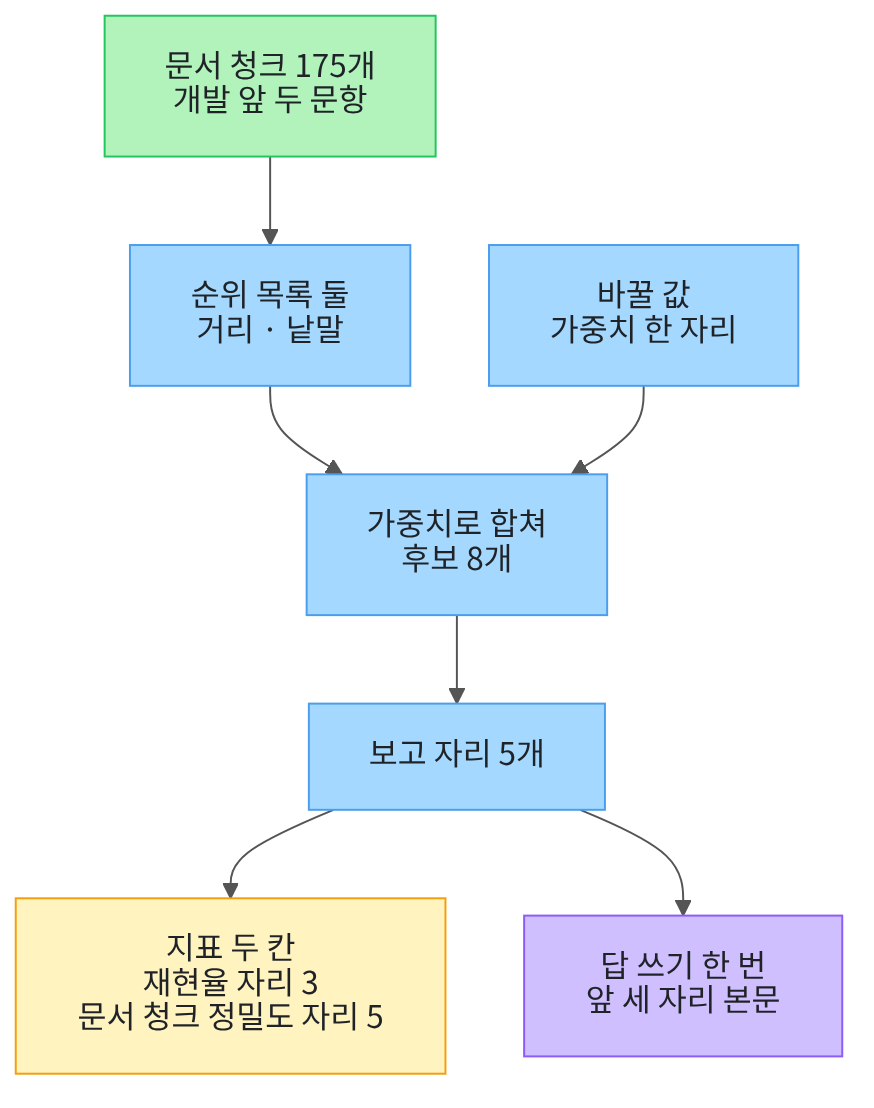

위에서 아래로 읽습니다. 맨 위 초록 상자는 노트북 3·5절에서 만드는 재료입니다.

파란 상자 네 개는 05~08절에서 배운 검색 단계이고 이 노트북이 같은 코드로 다시 정의합니다.
그 가운데 「바꿀 값」 상자가 이번 실습에서 손대는 자리입니다.
맨 아래 왼쪽 노란 상자는 지표 두 칸이고 오른쪽 보라 상자는 답을 쓰는 모델입니다.

## 1. 준비

첫 셀은 패키지 다섯 개를 설치하고 설치된 버전을 출력합니다.
11·12절과 같은 다섯 개입니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3" "kiwipiepy==0.23.2" "rank-bm25==0.2.2"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))
print("kiwipiepy:", version("kiwipiepy"))
print("rank-bm25:", version("rank-bm25"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0


langchain-openai: 1.6.1
python-dotenv: 1.2.3
kiwipiepy: 0.23.2
rank-bm25: 0.2.2


**결과 읽기** — 설치가 끝나면 `langchain: 1.4.0`과 `rank-bm25: 0.2.2`가 보입니다.
다섯 줄이 모두 보이면 다음 셀로 넘어갑니다.

다음 셀은 이 절에서 쓸 이름 일곱 개를 불러옵니다.

In [2]:
# 자료 읽기·제곱근·경로 확인과 이 절에서 쓸 검색 도구를 불러옵니다
import json
import math
import os

from kiwipiepy import Kiwi
from langchain.chat_models import init_chat_model
from langchain_openai import OpenAIEmbeddings
from rank_bm25 import BM25Okapi

print("불러온 이름:", "json", "math", "os", "Kiwi", "init_chat_model", "OpenAIEmbeddings", "BM25Okapi")

불러온 이름: json math os Kiwi init_chat_model OpenAIEmbeddings BM25Okapi


**결과 읽기** — 출력 줄은 `불러온 이름:` 뒤에 이름 일곱 개가 붙은 한 줄입니다.
12절이 쓰던 `hashlib`과 `time`은 부르지 않습니다.
이 절은 지문을 만들지 않고 파일도 쓰지 않기 때문입니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 문장을 고르게 합니다.
설정 `reasoning_effort="none"`은 답을 쓰기 전에 따로 생각하는 단계를 두지 않게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-19에 이 모델로 실행한 결과입니다.

다음 셀은 프로젝트 맨 위 폴더를 찾습니다. 01~12절과 같은 코드입니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part3/ch12-retrieval-tuning/data"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. 확인 줄도 통과했습니다.

다음 셀은 07~12절과 같은 자료 두 벌을 읽습니다.

In [6]:
# 07~12절과 같은 파일 두 벌을 읽습니다
data_path = root_path + "/labs/part3/ch12-retrieval-tuning/data"
with open(data_path + "/advanced-documents.json", encoding="utf-8") as file:
    documents = json.loads(file.read())
with open(data_path + "/advanced-queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
parents = documents["parents"]
chunks = documents["chunks"]
print("부모 문서 수:", len(parents))
print("문서 청크 수:", len(chunks))
print("질문 수:", len(queries))

부모 문서 수: 6
문서 청크 수: 175
질문 수: 30


**결과 읽기** — `부모 문서 수: 6`과 `문서 청크 수: 175`, `질문 수: 30`이 보입니다.
07~12절과 같은 파일이라 세 값도 같습니다.

## 2. 실습 주제 — 가중치 하나를 바꿔 답까지 보기

작은 안내 창구의 검색기를 손보는 일을 맡았다고 봅니다.
06절에서 뜻 검색 순위와 낱말 검색 순위를 가중치로 합쳤고, 08절에서 보고 자리를 다섯으로 정했습니다.
12절에서는 그 보고 자리의 본문을 모델에 넣어 답을 한 번 썼습니다.

이번 실습은 그 단계를 한 줄기로 잇고 **가중치 한 자리만** 바꿉니다.
실행 1은 두 검색에 같은 몫을 주고, 실행 2는 낱말 검색 쪽 몫을 0으로 내립니다.
바뀌는 값은 그 하나뿐이고 질문·문서·후보 수·보고 자리·모델은 모두 같게 둡니다.

## 3. 재료 만들기 — 값과 문서 청크 벡터

먼저 01~12절에서 쓴 값을 그대로 다시 정합니다.

In [7]:
# 01~12절에서 쓴 값을 그대로 다시 정하고 이번에 바꿔 볼 가중치 두 벌을 적습니다
similarity_top = 1
keep_tags = ["NNG", "NNP", "NNB", "NR", "VV", "VA", "MAG", "SN", "SL"]
rank_constant = 60
candidate_count = 8
recall_place = 3
report_place = 5
context_count = 3
question_take = 2
equal_weights = [1.0, 1.0]
dense_only_weights = [1.0, 0.0]
print("순위 상수:", rank_constant, "| 후보 수:", candidate_count, "| 보고 자리:", report_place)
print("재현율을 재는 자리:", recall_place, "| 모델에 넣을 자리 수:", context_count)
print("실행 1 가중치:", equal_weights, "| 실행 2 가중치:", dense_only_weights)

순위 상수: 60 | 후보 수: 8 | 보고 자리: 5
재현율을 재는 자리: 3 | 모델에 넣을 자리 수: 3
실행 1 가중치: [1.0, 1.0] | 실행 2 가중치: [1.0, 0.0]


**결과 읽기** — 줄 `순위 상수: 60 | 후보 수: 8 | 보고 자리: 5`는 06~12절과 같은 값입니다.
줄 `실행 1 가중치: [1.0, 1.0] | 실행 2 가중치: [1.0, 0.0]`이 이번에 바꿀 자리입니다.
앞 숫자가 뜻 검색 몫이고 뒤 숫자가 낱말 검색 몫입니다.

다음 셀은 문서 청크마다 제목과 본문을 이어 붙입니다.

In [8]:
# 문서 청크마다 제목과 본문을 이어 붙여 글 하나로 만듭니다(07~12절과 같은 코드)
chunk_texts = []
chunk_ids = []
for chunk in chunks:
    chunk_text = chunk["title"] + " " + chunk["text"]
    chunk_texts.append(chunk_text)
    chunk_ids.append(chunk["chunk_id"])
all_chunk_count = len(chunk_ids)
print("이어 붙인 글 수:", len(chunk_texts))
print("첫 문서 청크 ID:", chunk_ids[0])

이어 붙인 글 수: 175
첫 문서 청크 ID: E01-P01-C01


**결과 읽기** — `이어 붙인 글 수: 175`가 보입니다.
줄 `첫 문서 청크 ID: E01-P01-C01`의 이름 앞머리가 그 문서 청크의 부모 문서 ID입니다.

다음 셀은 문서 청크 ID로 부모와 쪽과 본문을 바로 찾을 수 있게 짝을 만듭니다.

In [9]:
# 문서 청크 ID로 부모 문서 ID와 쪽 번호와 본문을 바로 찾게 짝을 만듭니다(12절과 같은 코드)
parent_by_chunk = {}
page_by_chunk = {}
text_by_chunk = {}
for i in range(len(chunks)):
    chunk_id = chunk_ids[i]
    parent_by_chunk[chunk_id] = chunks[i]["parent_id"]
    page_by_chunk[chunk_id] = chunks[i]["page"]
    text_by_chunk[chunk_id] = chunk_texts[i]
print("짝지은 문서 청크 수:", len(parent_by_chunk))
print("첫 문서 청크의 부모 문서 ID:", parent_by_chunk[chunk_ids[0]])
print("첫 문서 청크의 쪽 번호:", page_by_chunk[chunk_ids[0]])

짝지은 문서 청크 수: 175
첫 문서 청크의 부모 문서 ID: E01
첫 문서 청크의 쪽 번호: 1


**결과 읽기** — `짝지은 문서 청크 수: 175`가 보입니다.
줄 `첫 문서 청크의 부모 문서 ID: E01`과 `첫 문서 청크의 쪽 번호: 1`은 출처 표시에 쓸 값입니다.

다음 셀은 문서 청크를 벡터로 바꿉니다. 01~12절과 같은 모델과 같은 차원 수입니다.

In [10]:
# 01~12절과 같은 모델로 문서 청크를 벡터로 바꿉니다(임베딩 요청 1번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
chunk_vectors = embedding_model.embed_documents(chunk_texts)
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 청크 벡터 수:", len(chunk_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 청크 벡터 수: 175


**결과 읽기** — `벡터의 숫자 개수 설정: 256`과 `문서 청크 벡터 수: 175`가 보입니다.
여기까지 임베딩 요청은 한 번입니다.

## 4. 앞 절에서 만든 함수 다시 만들기

다음 여덟 셀은 01~12절에서 만든 함수 열세 개를 같은 코드로 다시 정의합니다.
셀마다 첫 줄 주석에 어느 절 함수인지 적었습니다.
앞 절에서 이미 읽은 코드라 셀 하나에 함수를 둘이나 셋씩 담았습니다.
모두 정의 셀이라 출력이 없습니다.

In [11]:
# 01절 점곱·길이·코사인 유사도 함수를 같은 코드로 다시 정의합니다
def dot_product(first, second):
    total = 0
    # 반복 번호 i로 두 벡터의 같은 자리 숫자를 짝지어 곱하고 더합니다
    for i in range(len(first)):
        total = total + first[i] * second[i]
    return total


def vector_length(vector):
    squared_sum = dot_product(vector, vector)
    return math.sqrt(squared_sum)


def cosine_similarity(first, second):
    dot = dot_product(first, second)
    length_product = vector_length(first) * vector_length(second)
    return dot / length_product

In [12]:
# 01절 코사인 거리와 04~12절 형태소 고르기를 같은 코드로 다시 정의합니다
def cosine_distance(first, second):
    similarity = cosine_similarity(first, second)
    return similarity_top - similarity


kiwi = Kiwi()


def kiwi_terms(text):
    terms = []
    for token in kiwi.tokenize(text):
        # 조사와 어미는 품사 표시가 목록에 없어 빠집니다
        if token.tag in keep_tags:
            terms.append(token.form)
    return terms

In [13]:
# 05~12절과 같은 코드로 거리가 작은 순서의 순위 목록을 만듭니다
def rank_by_distance(question_vector, top_count):
    pairs = []
    for i in range(len(chunk_ids)):
        distance = cosine_distance(question_vector, chunk_vectors[i])
        pairs.append((distance, chunk_ids[i]))
    hit_list = []
    for pair in sorted(pairs):
        hit_list.append({"chunk_id": pair[1], "거리": round(pair[0], 2)})
    return hit_list[:top_count]

In [14]:
# 05~12절과 같은 코드로 낱말 겹침 점수가 큰 순서의 순위 목록을 만듭니다
def rank_by_bm25(question, top_count):
    question_terms = kiwi_terms(question)
    scores = bm25_model.get_scores(question_terms)
    pairs = []
    for i in range(len(chunk_ids)):
        # 점수에 음수를 붙이면 sorted가 큰 점수를 앞으로 보냅니다
        pairs.append((0 - scores[i], chunk_ids[i]))
    hit_list = []
    for pair in sorted(pairs):
        hit_list.append({"chunk_id": pair[1], "점수": round(0 - pair[0], 2)})
    return hit_list[:top_count]

In [15]:
# 07~12절 문서 청크 ID 모으기와 부모 문서 ID로 바꾸기를 같은 코드로 다시 정의합니다
def unique_chunk_ids(hit_list):
    found_ids = []
    for hit in hit_list:
        if hit["chunk_id"] not in found_ids:
            found_ids.append(hit["chunk_id"])
    return found_ids


def parent_ids_of(found_chunk_ids):
    parent_ids = []
    for chunk_id in found_chunk_ids:
        parent_id = parent_by_chunk[chunk_id]
        # 여러 문서 청크가 같은 부모를 가리키면 처음 나온 자리만 남깁니다
        if parent_id not in parent_ids:
            parent_ids.append(parent_id)
    return parent_ids

In [16]:
# 06~12절과 같은 코드로 순위 목록 여러 개의 자리 몫을 더합니다
def fuse_scores(ranking_list, weight_list):
    scores = {}
    for list_index in range(len(ranking_list)):
        ranking = ranking_list[list_index]
        weight = weight_list[list_index]
        # 자리 번호는 1부터 세고 앞자리일수록 나누는 수가 작아 몫이 큽니다
        for position in range(len(ranking)):
            chunk_id = ranking[position]
            share = weight / (rank_constant + position + 1)
            scores[chunk_id] = scores.get(chunk_id, 0.0) + share
    return scores

In [17]:
# 06~12절과 같은 코드로 합친 점수가 큰 순서의 문서 청크 ID 목록을 만듭니다
def fuse_rank(ranking_list, weight_list):
    scores = fuse_scores(ranking_list, weight_list)
    pairs = []
    for chunk_id in scores:
        pairs.append((0 - scores[chunk_id], chunk_id))
    fused_ids = []
    for pair in sorted(pairs):
        fused_ids.append(pair[1])
    return fused_ids

In [18]:
# Ch 11 02절 재현율과 08~12절 문서 청크 정밀도를 같은 코드로 다시 정의합니다
def recall_at(doc_ids, gold_doc_ids, cutoff):
    top_ids = doc_ids[:cutoff]
    found_count = 0
    for gold_id in gold_doc_ids:
        if gold_id in top_ids:
            found_count = found_count + 1
    return found_count / len(gold_doc_ids)


def chunk_precision_at(found_chunk_ids, gold_doc_ids, cutoff):
    top_ids = found_chunk_ids[:cutoff]
    found_count = 0
    for chunk_id in top_ids:
        if parent_by_chunk[chunk_id] in gold_doc_ids:
            found_count = found_count + 1
    return found_count / cutoff

여기까지가 다시 만든 함수입니다. 두 가지만 짚고 넘어갑니다.

리랭커와 MMR은 이 실습에서 쓰지 않아 다시 만들지 않았습니다.
보고 자리 다섯 개는 합친 순위의 앞자리를 그대로 씁니다.

## 5. 검색 재료 마무리 — BM25 모델과 질문 두 개

다음 셀은 문서 청크의 검색 낱말 목록으로 BM25 모델을 만듭니다.

In [19]:
# 문서 청크마다 검색 낱말 목록을 만들고 그 목록으로 BM25 모델을 만듭니다(04~12절과 같은 코드)
kiwi_corpus = []
for text_value in chunk_texts:
    kiwi_corpus.append(kiwi_terms(text_value))
bm25_model = BM25Okapi(kiwi_corpus)
print("검색 낱말 목록 수:", len(kiwi_corpus))
print("BM25 모델이 본 문서 청크 수:", bm25_model.corpus_size)
print("문서 청크 하나의 평균 검색 낱말 수:", round(bm25_model.avgdl, 2))

검색 낱말 목록 수: 175
BM25 모델이 본 문서 청크 수: 175
문서 청크 하나의 평균 검색 낱말 수: 44.01


**결과 읽기** — `검색 낱말 목록 수: 175`와 `BM25 모델이 본 문서 청크 수: 175`가 보입니다.
줄 `문서 청크 하나의 평균 검색 낱말 수: 44.01`은 07~12절과 같은 값입니다.

다음 셀은 개발 묶음에서 앞 두 문항만 고릅니다.
Ch 11이 정한 약속대로 시험 15문항은 이 절에서도 열지 않습니다.
질문을 둘로 줄인 까닭은 요청을 다섯 번 안으로 두기 위해서입니다.

In [20]:
# 개발 묶음에서 앞 두 문항만 골라 질문 글과 정답 부모 문서 ID를 짝지어 둡니다
dev_queries = []
for query in queries:
    if query["split"] == "dev":
        dev_queries.append(query)
practice_items = dev_queries[:question_take]
question_ids = []
gold_by_qid = {}
question_by_qid = {}
for item in practice_items:
    question_ids.append(item["qid"])
    gold_by_qid[item["qid"]] = item["gold_doc_ids"]
    question_by_qid[item["qid"]] = item["question"]
print("개발 질문 수:", len(dev_queries), "| 이번에 쓸 질문 수:", len(question_ids))
print("고른 질문 ID:", question_ids)

개발 질문 수: 15 | 이번에 쓸 질문 수: 2
고른 질문 ID: ['Q001', 'Q002']


**결과 읽기** — `개발 질문 수: 15 | 이번에 쓸 질문 수: 2`가 보입니다.
줄 `고른 질문 ID: ['Q001', 'Q002']`가 이번 실습의 질문 두 개입니다.
두 질문은 07~12절에서도 쓰던 개발 묶음 앞자리 문항입니다.

다음 셀은 질문마다 벡터와 순위 목록 두 개를 미리 만듭니다.
가중치가 바뀌어도 이 두 목록은 그대로라 한 번만 만들면 됩니다.

In [21]:
# 고른 질문마다 벡터와 순위 목록 두 개를 미리 만듭니다(임베딩 요청 2번)
lists_by_qid = {}
for question_id in question_ids:
    question = question_by_qid[question_id]
    question_vector = embedding_model.embed_query(question)
    distance_hits = rank_by_distance(question_vector, all_chunk_count)
    score_hits = rank_by_bm25(question, all_chunk_count)
    lists_by_qid[question_id] = [unique_chunk_ids(distance_hits), unique_chunk_ids(score_hits)]
first_id = question_ids[0]
print("질문 하나의 순위 목록 수:", len(lists_by_qid[first_id]))
print("순위 목록 하나의 문서 청크 수:", len(lists_by_qid[first_id][0]))
print("거리 순위 1위 문서 청크:", lists_by_qid[first_id][0][0])
print("낱말 순위 1위 문서 청크:", lists_by_qid[first_id][1][0])

질문 하나의 순위 목록 수: 2
순위 목록 하나의 문서 청크 수: 175
거리 순위 1위 문서 청크: E01-P02-C04
낱말 순위 1위 문서 청크: E01-P02-C04


**결과 읽기** — `질문 하나의 순위 목록 수: 2`와 `순위 목록 하나의 문서 청크 수: 175`가 보입니다.
두 줄 아래 `거리 순위 1위 문서 청크: E01-P02-C04`와 `낱말 순위 1위 문서 청크: E01-P02-C04`는 첫 질문 값입니다.
첫 질문에서는 두 순위의 1위가 같았습니다.
여기까지 임베딩 요청은 세 번입니다.

## 6. 결과를 볼 기록 장치

실행마다 무엇을 볼지 먼저 정합니다.
질문별로 부모 문서 차례와 지표 두 칸을 한 줄씩 적고, 그 아래에 질문 평균을 냅니다.

In [22]:
# 질문별 줄을 라벨 줄 아래에 한 줄씩 적고 지표 칸의 질문 평균을 냅니다
def print_rows(rows):
    print("질문 | 부모 문서 차례 | 재현율 자리 3 | 문서 청크 정밀도 자리 5")
    for row in rows:
        print(row["질문"], "|", row["부모 문서 차례"], "|", row["재현율 자리 3"], "|", row["문서 청크 정밀도 자리 5"])


def column_mean(rows, name):
    total = 0.0
    for row in rows:
        total = total + row[name]
    return round(total / len(rows), 2)

정의 셀이라 출력이 없습니다.
첫 함수는 라벨 줄을 먼저 내고 질문마다 한 줄씩 적습니다.
둘째 함수는 줄 목록에서 지표 칸만 모아 질문 평균을 소수 둘째 자리까지 냅니다.

다음 셀은 고른 문서 청크를 모델에 넣을 글로 바꾸는 함수입니다.
출처 표시는 Ch 8과 12절에서 쓴 `[문서ID p.쪽]` 모양 그대로입니다.

In [23]:
# 고른 문서 청크의 앞자리 본문과 출처 표시를 이어 붙여 모델에 넣을 글을 만듭니다(12절과 같은 모양)
def context_of(picked_ids):
    context_ids = picked_ids[:context_count]
    context_text = ""
    for chunk_id in context_ids:
        source_label = "[" + parent_by_chunk[chunk_id] + " p." + str(page_by_chunk[chunk_id]) + "]"
        context_text = context_text + source_label + "\n" + text_by_chunk[chunk_id] + "\n\n"
    return context_text

정의 셀이라 출력이 없습니다.
앞 세 자리만 넣습니다. 보고 자리는 다섯이지만 수업 시간에 눈으로 읽을 만큼만 넣습니다.
자리마다 출처 표시 한 줄과 본문 한 줄을 붙이고 빈 줄로 나눕니다.

## 7. 조립 — 배운 단계를 한 함수로 잇기

다음 셀이 이 실습의 조립 함수입니다.
주석에 어느 절에서 배운 단계인지 적었습니다.

In [24]:
# 질문 하나를 가중치대로 검색해 고른 자리와 지표 두 개를 한 줄로 만듭니다
def score_row(question_id, weight_list):
    # 06절: 순위 목록 두 개를 가중치로 합쳐 앞자리 여덟 개를 후보로 자릅니다
    fused_ids = fuse_rank(lists_by_qid[question_id], weight_list)
    found_ids = fused_ids[:candidate_count]
    # 08절: 후보 앞에서 보고 자리 다섯 개만 남깁니다
    picked_ids = found_ids[:report_place]
    # 07절: 고른 문서 청크를 부모 문서 차례로 바꿉니다
    parent_ids = parent_ids_of(picked_ids)
    gold_ids = gold_by_qid[question_id]
    row = {"질문": question_id, "고른 문서 청크": picked_ids, "부모 문서 차례": parent_ids}
    # Ch 11 02절 재현율과 08절 문서 청크 정밀도
    row["재현율 자리 3"] = recall_at(parent_ids, gold_ids, recall_place)
    row["문서 청크 정밀도 자리 5"] = chunk_precision_at(picked_ids, gold_ids, report_place)
    return row

정의 셀이라 출력이 없습니다.
차례는 네 단계입니다. 순위 합치기, 후보 자르기, 보고 자리 남기기, 지표 두 칸 재기입니다.
07~12절에서 하나씩 배운 단계를 한 줄씩 이어 붙인 것입니다.

다음 셀은 가중치 한 벌을 질문 두 개 모두에 적용합니다.

In [25]:
# 가중치 한 벌을 고른 질문 모두에 적용해 줄 목록을 냅니다
def run_weights(weight_list):
    rows = []
    for question_id in question_ids:
        rows.append(score_row(question_id, weight_list))
    return rows

정의 셀이라 출력이 없습니다.
받는 값은 가중치 목록 하나뿐입니다. 질문 묶음과 나머지 설정은 바깥에 정해 둔 값을 씁니다.
그래서 두 실행이 가중치 말고는 같은 조건이 됩니다.

## 8. 실행 1 — 두 검색에 같은 몫

첫 실행은 06절 기본 가중치입니다. 뜻 검색과 낱말 검색에 같은 몫을 줍니다.

실행 전에 예상합니다. 두 질문 모두 정답 부모가 `E01` 하나라 부모 문서 차례가 짧을 것입니다.

In [26]:
# 실행 1: 06절 기본 가중치로 두 질문을 재고 표로 봅니다
run1_rows = run_weights(equal_weights)
print_rows(run1_rows)
print("실행 1 재현율 자리 3 평균:", column_mean(run1_rows, "재현율 자리 3"))
print("실행 1 문서 청크 정밀도 자리 5 평균:", column_mean(run1_rows, "문서 청크 정밀도 자리 5"))
print("실행 1이 Q002에서 고른 문서 청크:", run1_rows[1]["고른 문서 청크"])

질문 | 부모 문서 차례 | 재현율 자리 3 | 문서 청크 정밀도 자리 5
Q001 | ['E01'] | 1.0 | 1.0
Q002 | ['E01'] | 1.0 | 1.0
실행 1 재현율 자리 3 평균: 1.0
실행 1 문서 청크 정밀도 자리 5 평균: 1.0
실행 1이 Q002에서 고른 문서 청크: ['E01-P03-C02', 'E01-P04-C06', 'E01-P03-C01', 'E01-P03-C08', 'E01-P03-C04']


**결과 읽기** — 라벨 줄 아래 두 줄이 나옵니다.
줄 `Q001 | ['E01'] | 1.0 | 1.0`과 `Q002 | ['E01'] | 1.0 | 1.0`입니다.
두 질문 모두 보고 자리 다섯 개가 전부 정답 부모의 문서 청크였습니다.

평균 두 줄도 `1.0`입니다.
맨 아래 줄 `실행 1이 Q002에서 고른 문서 청크:` 뒤 다섯 개가 모두 `E01`로 시작합니다.

다음 셀은 두 실행에서 똑같이 쓸 부탁 글과 답을 쓸 질문을 정합니다.

In [27]:
# 두 실행에서 똑같이 쓸 부탁 글과 답을 쓸 질문을 정합니다
prompt_head = "아래 자료만 보고 질문에 한국어로 답하세요.\n"
prompt_head = prompt_head + "답 끝에 [문서ID p.쪽] 모양으로 출처를 적으세요.\n\n"
answer_qid = question_ids[1]
answer_question = question_by_qid[answer_qid]
print("답을 쓸 질문:", answer_qid, "|", answer_question)
print("그 질문의 정답 부모 문서 ID:", gold_by_qid[answer_qid])

답을 쓸 질문: Q002 | 도서는 한 번에 몇 권까지, 며칠 동안 빌릴 수 있나요?
그 질문의 정답 부모 문서 ID: ['E01']


**결과 읽기** — 줄 `답을 쓸 질문: Q002 | 도서는 한 번에 몇 권까지, 며칠 동안 빌릴 수 있나요?`가 보입니다.
줄 `그 질문의 정답 부모 문서 ID: ['E01']`도 함께 나옵니다.
부탁 글은 「넣은 자료만 보고 답하고 끝에 출처를 적으라」는 두 문장입니다.

다음 셀이 실행 1의 답을 씁니다. 이 챕터에서 답을 쓰는 모델을 부르는 자리입니다.

In [28]:
# 실행 1이 고른 앞 세 자리 본문으로 답을 씁니다(모델 요청 1번)
run1_context = context_of(run1_rows[1]["고른 문서 청크"])
run1_prompt = prompt_head + "질문: " + answer_question + "\n\n자료:\n" + run1_context
run1_answer = model.invoke(run1_prompt)
run1_text = run1_answer.text.strip()
print("넣은 글의 길이:", len(run1_context))
print("실행 1의 답:", run1_text)

넣은 글의 길이: 432
실행 1의 답: 도서는 한 번에 7권까지 빌릴 수 있고, 대출 기간은 14일입니다. [E01 p.3]


**결과 읽기** — 줄 `넣은 글의 길이: 432`는 모델에 넣은 글의 글자 수입니다.
줄 `실행 1의 답:` 뒤에 한 문장과 출처 표시가 나옵니다.
답에 적힌 출처가 넣은 자리 안에 있는지 눈으로 확인합니다.
모델이 쓴 문장은 실행마다 달라질 수 있어 낱말을 확인 줄로 보지 않았습니다.

## 9. 실행 2 — 낱말 검색 몫을 0으로

이제 값 하나만 바꿉니다. 가중치를 `[1.0, 0.0]`으로 두어 뜻 검색 순위만 씁니다.
질문 묶음과 문서, 후보 수 8, 보고 자리 5, 모델은 실행 1과 같습니다.

실행 전에 예상합니다. 낱말이 그대로 겹치던 문서 청크가 앞에서 밀려나 정밀도가 내려갈 것입니다.

In [29]:
# 실행 2: 가중치만 [1.0, 0.0]으로 바꿔 같은 순위 목록을 다시 씁니다
run2_rows = run_weights(dense_only_weights)
print_rows(run2_rows)
print("실행 2 재현율 자리 3 평균:", column_mean(run2_rows, "재현율 자리 3"))
print("실행 2 문서 청크 정밀도 자리 5 평균:", column_mean(run2_rows, "문서 청크 정밀도 자리 5"))
print("실행 2가 Q002에서 고른 문서 청크:", run2_rows[1]["고른 문서 청크"])

질문 | 부모 문서 차례 | 재현율 자리 3 | 문서 청크 정밀도 자리 5
Q001 | ['E01'] | 1.0 | 1.0
Q002 | ['E01', 'E02'] | 1.0 | 0.4
실행 2 재현율 자리 3 평균: 1.0
실행 2 문서 청크 정밀도 자리 5 평균: 0.7
실행 2가 Q002에서 고른 문서 청크: ['E01-P04-C06', 'E01-P03-C08', 'E02-P05-C01', 'E02-P03-C02', 'E02-P03-C04']


**결과 읽기** — 라벨 줄 아래 첫 줄 `Q001 | ['E01'] | 1.0 | 1.0`은 실행 1과 같습니다.
둘째 줄은 `Q002 | ['E01', 'E02'] | 1.0 | 0.4`로 바뀌었습니다.
질문 `Q002`의 보고 자리 다섯 가운데 세 자리가 다른 부모 문서 `E02`의 문서 청크입니다.

줄 `실행 2 문서 청크 정밀도 자리 5 평균: 0.7`이 실행 1보다 낮습니다.
재현율 자리 3 평균은 두 실행 모두 `1.0`입니다.

다음 셀이 실행 2가 고른 자리로 같은 질문에 답을 씁니다.

In [30]:
# 실행 2가 고른 앞 세 자리 본문으로 같은 질문에 답을 씁니다(모델 요청 1번)
run2_context = context_of(run2_rows[1]["고른 문서 청크"])
run2_prompt = prompt_head + "질문: " + answer_question + "\n\n자료:\n" + run2_context
run2_answer = model.invoke(run2_prompt)
run2_text = run2_answer.text.strip()
print("넣은 글의 길이:", len(run2_context))
print("실행 2의 답:", run2_text)

넣은 글의 길이: 302
실행 2의 답: 제공된 자료에는 도서 대출 권수나 대출 기간에 대한 정보가 없습니다. 따라서 한 번에 몇 권까지, 며칠 동안 빌릴 수 있는지 확인할 수 없습니다. [E01 p.3]


**결과 읽기** — 줄 `넣은 글의 길이: 302`는 실행 1보다 짧습니다.
줄 `실행 2의 답:` 뒤 문장은 자료에서 권수와 기간을 찾지 못했다는 내용입니다.
넣은 세 자리 가운데 대출 권수와 기간이 적힌 자리가 없었기 때문입니다.
답 끝에는 출처 표시가 그대로 붙어 있습니다. 이 한 번만 본 모습입니다.

## 10. 두 실행 비교

마지막으로 두 실행의 질문 평균을 한 표로 모읍니다.

실행 전에 예상합니다. 재현율은 같고 문서 청크 정밀도만 갈릴 것입니다.

In [31]:
# 두 실행의 질문 평균을 한 표로 모아 나란히 봅니다
compare_rows = [["실행 1", equal_weights, run1_rows], ["실행 2", dense_only_weights, run2_rows]]
print("실행 | 가중치 | 재현율 자리 3 평균 | 문서 청크 정밀도 자리 5 평균")
for entry in compare_rows:
    recall_mean = column_mean(entry[2], "재현율 자리 3")
    chunk_mean = column_mean(entry[2], "문서 청크 정밀도 자리 5")
    print(entry[0], "|", entry[1], "|", recall_mean, "|", chunk_mean)

실행 | 가중치 | 재현율 자리 3 평균 | 문서 청크 정밀도 자리 5 평균
실행 1 | [1.0, 1.0] | 1.0 | 1.0
실행 2 | [1.0, 0.0] | 1.0 | 0.7


**결과 읽기** — 라벨 줄 아래 두 줄이 나옵니다.
위 줄은 `실행 1 | [1.0, 1.0] | 1.0 | 1.0`이고 아래 줄은 `실행 2 | [1.0, 0.0] | 1.0 | 0.7`입니다.
가중치 한 자리를 바꾸자 문서 청크 정밀도 평균만 내려갔습니다.

재현율 자리 3은 두 줄이 모두 `1.0`이라 이 조건에서는 두 실행을 가르지 못합니다.
07~12절에서 본 천장이 질문 두 개에서도 그대로였습니다.

## 정리

1. 순위 합치기와 보고 자리와 지표와 답 쓰기를 한 함수 줄기로 이었습니다.
2. 가중치 한 자리만 바꾸자 `Q002`의 보고 자리 다섯 가운데 세 자리가 다른 부모 문서로 바뀌었습니다.
3. 넣은 자료가 달라지자 같은 질문에 대한 답도 달라졌습니다.

이 절로 Ch 12가 끝납니다. Ch 13에서는 이 챕터가 남긴 통합 기록을 읽어 흐름도로 잇습니다.